In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


# Membaca Data dan filter kejadian

In [2]:

Target = "Magnitude"
Fitur = [
    "Latitude",
    "Longitude",
    "Depth",
    "Depth Seismic Stations",
    "Year",
    "Month",
    "Hour"
]

data = pd.read_csv("database.csv")
print(f"Baris awal            : {len(data)}")

data = data[data["Type"] == "Earthquake"].copy()
print(f"Setelah filter Earthquake: {len(data)}")
print(data.columns.tolist())



Baris awal            : 23412
Setelah filter Earthquake: 23232
['Date', 'Time', 'Latitude', 'Longitude', 'Type', 'Depth', 'Depth Error', 'Depth Seismic Stations', 'Magnitude', 'Magnitude Type', 'Magnitude Error', 'Magnitude Seismic Stations', 'Azimuthal Gap', 'Horizontal Distance', 'Horizontal Error', 'Root Mean Square', 'ID', 'Source', 'Location Source', 'Magnitude Source', 'Status']


# Menggabungkan date + time menjadi datetime, buang yang gagal parse

In [3]:

data["datetime"] = pd.to_datetime(
    data["Date"] + " " + data["Time"],
    format="%m/%d/%Y %H:%M:%S",
    errors="coerce",
)
print(f"Tanggal/waktu tidak valid: {data['datetime'].isna().sum()}")
data = data.dropna(subset=["datetime"]).copy()
data.info()

Tanggal/waktu tidak valid: 3
<class 'pandas.core.frame.DataFrame'>
Index: 23229 entries, 0 to 23411
Data columns (total 22 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   Date                        23229 non-null  object        
 1   Time                        23229 non-null  object        
 2   Latitude                    23229 non-null  float64       
 3   Longitude                   23229 non-null  float64       
 4   Type                        23229 non-null  object        
 5   Depth                       23229 non-null  float64       
 6   Depth Error                 4448 non-null   float64       
 7   Depth Seismic Stations      7083 non-null   float64       
 8   Magnitude                   23229 non-null  float64       
 9   Magnitude Type              23226 non-null  object        
 10  Magnitude Error             315 non-null    float64       
 11  Magnitude Seismic Stations  24

# Membagi format waktu

In [4]:
data["Year"] = data["datetime"].dt.year
data["Month"] = data["datetime"].dt.month
data["Hour"] = data["datetime"].dt.hour

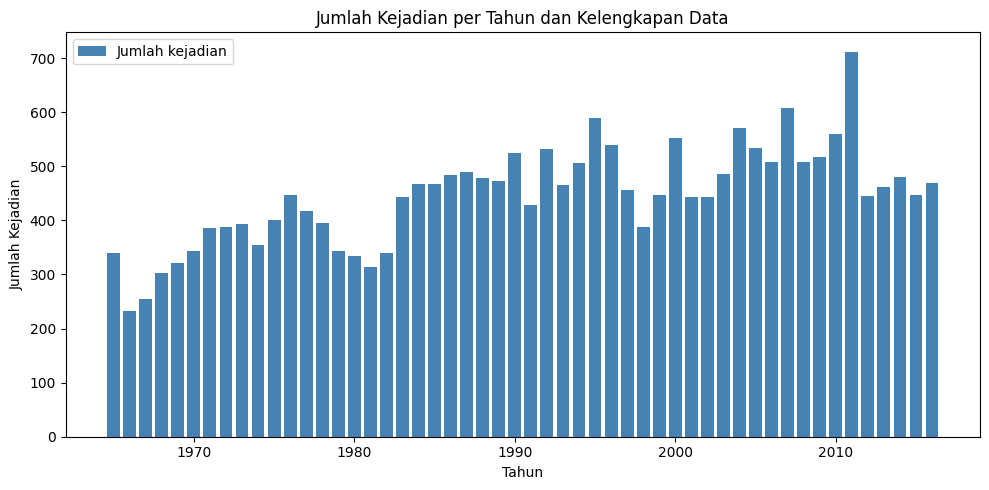

In [5]:

per_tahun = data.groupby("Year").size()
# kosong_pct = data.groupby("Year")[kolom_kualitas].apply(
#     lambda s: s.isna().mean() * 100
# )

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.bar(per_tahun.index, per_tahun.values, color="steelblue",
        label="Jumlah kejadian")
ax1.set_xlabel("Tahun")
ax1.set_ylabel("Jumlah Kejadian")

lines1, labels1 = ax1.get_legend_handles_labels()
ax1.legend(lines1, labels1 , loc="upper left")
ax1.set_title("Jumlah Kejadian per Tahun dan Kelengkapan Data")
plt.tight_layout()
plt.savefig("gambar_z_kejadian_per_tahun.png", dpi=300)

#sajbds


In [6]:
data = data[["datetime"] + Fitur + [Target]].copy()

data.to_csv("gempa_clean.csv", index=False)

#jadnba


In [7]:
year = data["datetime"].dt.year
train = data[year <= 2000]
val = data[(year > 2000) & (year <= 2010)]
test = data[year > 2010]

print(f"\nTrain: {len(train)} | Val: {len(val)} | Test: {len(test)}")

X_train, y_train = train[Fitur], train[Target]
X_val, y_val = val[Fitur], val[Target]
X_test, y_test = test[Fitur], test[Target]


Train: 15040 | Val: 5176 | Test: 3013


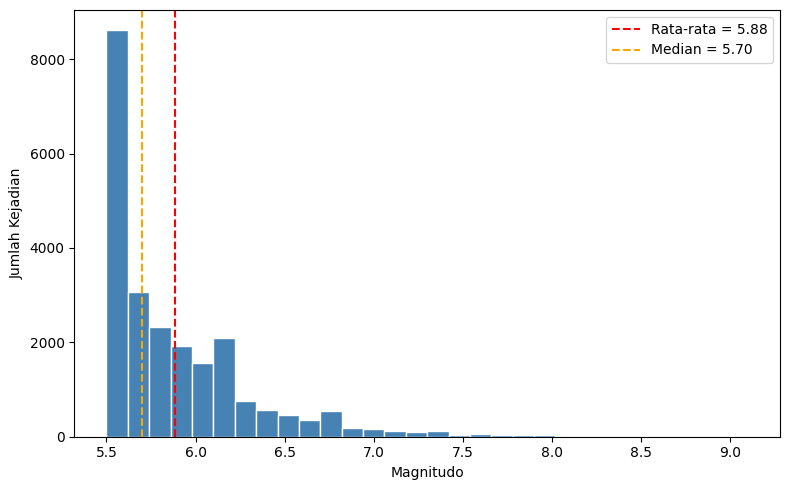

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(data["Magnitude"], bins=30, color="steelblue", edgecolor="white")
ax.set_xlabel("Magnitudo")
ax.set_ylabel("Jumlah Kejadian")
ax.axvline(data["Magnitude"].mean(), color="red", linestyle="--",
           label=f"Rata-rata = {data['Magnitude'].mean():.2f}")
ax.axvline(data["Magnitude"].median(), color="orange", linestyle="--",
           label=f"Median = {data['Magnitude'].median():.2f}")
ax.legend()

plt.tight_layout()
plt.savefig("gambar_x_histogram_magnitudo.png", dpi=300)
plt.show()

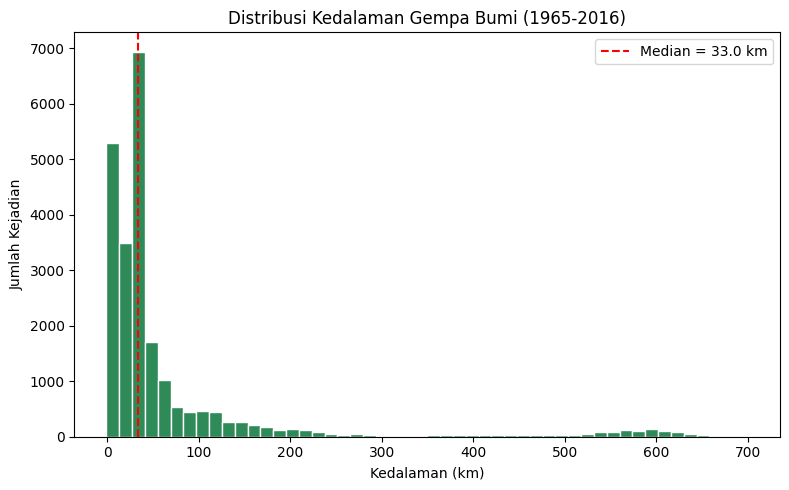

In [9]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(data["Depth"], bins=50, color="seagreen", edgecolor="white")
ax.axvline(data["Depth"].median(), color="red", linestyle="--",
           label=f"Median = {data['Depth'].median():.1f} km")
ax.set_title("Distribusi Kedalaman Gempa Bumi (1965-2016)")
ax.set_xlabel("Kedalaman (km)")
ax.set_ylabel("Jumlah Kejadian")
ax.legend()
plt.tight_layout()
plt.savefig("gambar_y_distribusi_kedalaman.png", dpi=300)

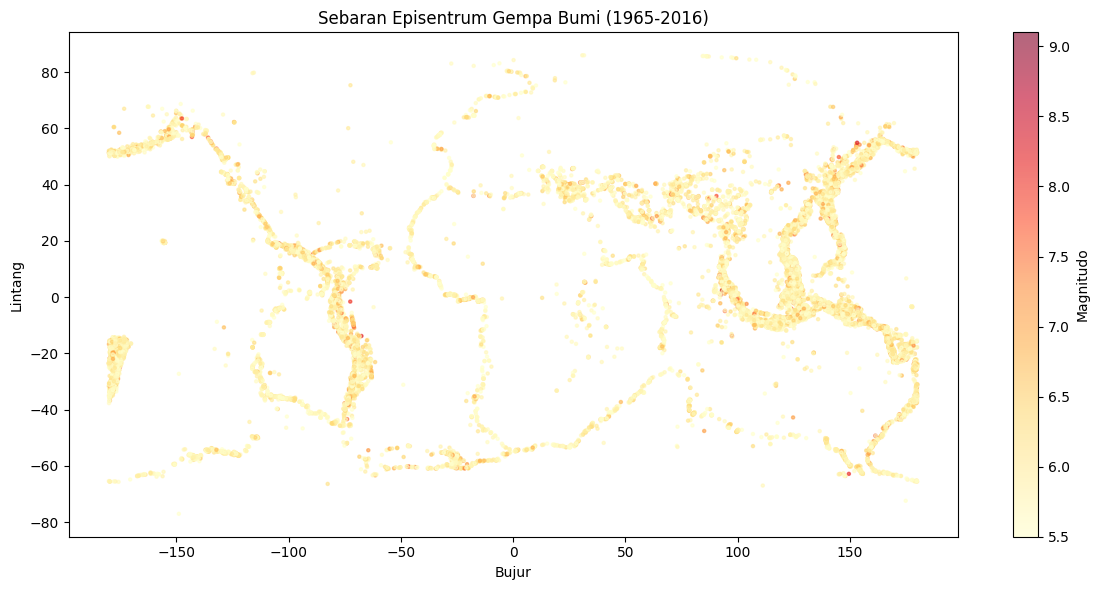

In [10]:
fig, ax = plt.subplots(figsize=(12, 6))
sc = ax.scatter(data["Longitude"], data["Latitude"], c=data["Magnitude"],
                cmap="YlOrRd", s=5, alpha=0.6)
plt.colorbar(sc, ax=ax, label="Magnitudo")
ax.set_title("Sebaran Episentrum Gempa Bumi (1965-2016)")
ax.set_xlabel("Bujur")
ax.set_ylabel("Lintang")
plt.tight_layout()
plt.savefig("gambar_w_sebaran_spasial.png", dpi=300)

Korelasi Spearman Depth-Magnitude: -0.037


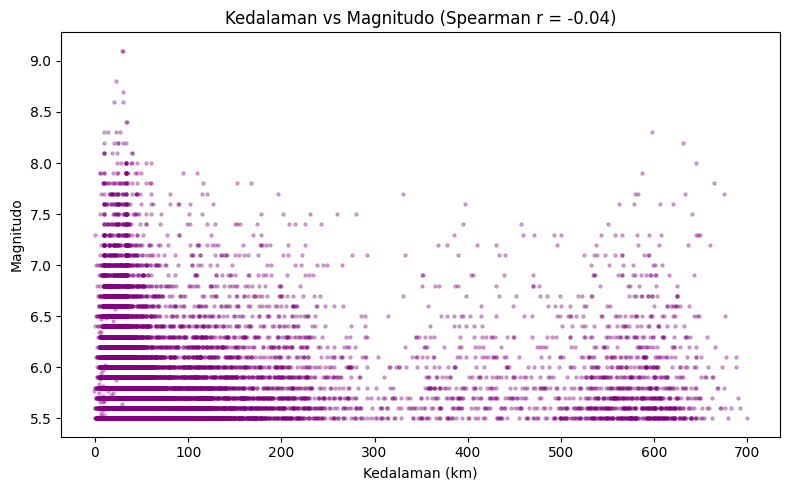

In [11]:
korelasi = data["Depth"].corr(data["Magnitude"], method="spearman")
print(f"Korelasi Spearman Depth-Magnitude: {korelasi:.3f}")

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(data["Depth"], data["Magnitude"], s=5, alpha=0.3, color="purple")
ax.set_title(f"Kedalaman vs Magnitudo (Spearman r = {korelasi:.2f})")
ax.set_xlabel("Kedalaman (km)")
ax.set_ylabel("Magnitudo")
plt.tight_layout()
plt.savefig("gambar_v_depth_vs_magnitudo.png", dpi=300)

plt.show()